# 3. Convergencia y comparación con `solve_bvp`

Seguimos con el problema de Robin del cuaderno 2:

$$
y'' = -\left(y'\right)^2, \qquad x \in [0, 1], \qquad
y(0) + y'(0) = 1, \quad y(1) - y'(1) = \ln 2 - \frac{1}{2},
$$

con solución exacta $y = \ln(1 + x)$ y parámetro $t = y(0)$, $t^\ast = 0$.
Estudiamos qué valores iniciales hacen converger a la secante y a Newton.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp

from bvp import Robin, newton_shooting, secant_shooting


def f(x, y, dy):
    return -dy**2


def f_y(x, y, dy):
    return 0.0


def f_dy(x, y, dy):
    return -2 * dy


left = Robin(1, 1, 1)
right = Robin(1, -1, np.log(2) - 0.5)

## Por qué algunos disparos explotan

La solución general de $y'' = -(y')^2$ es $y = \ln(x + c) + d$. Con
$y'(0) = 1 - t$ resulta $c = 1/(1 - t)$, y la solución deja de existir
dentro de $[0, 1]$ cuando $x + c$ se anula, es decir, si $-1 < c < 0$:

$$
t > 2 \quad\Longrightarrow\quad y'(0) < -1
\quad\Longrightarrow\quad \text{la solución explota antes de } x = 1 .
$$

Para esos $t$ no podemos evaluar $F(t)$, y el método falla si alguna
iteración cae ahí. Esto es típico del disparo no lineal: el problema de
valor inicial puede no tener solución en todo el intervalo.

En este ejemplo conocemos $F$ en forma cerrada (cuaderno 2):

$$
F(t) = t + \ln(2 - t) - \frac{1 - t}{2 - t} - \ln 2 + \frac{1}{2},
\qquad t < 2 .
$$

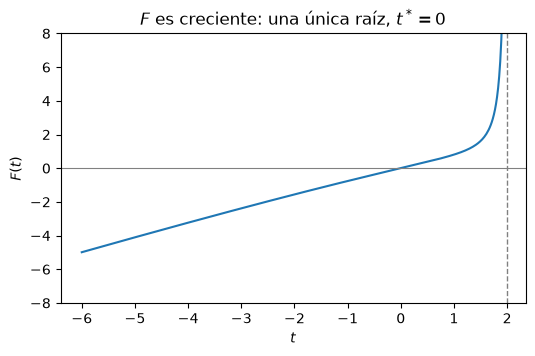

In [2]:
def F_exact(t):
    return t + np.log(2 - t) - (1 - t) / (2 - t) - np.log(2) + 0.5


ts = np.linspace(-6, 1.95, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ts, F_exact(ts))
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(2, color="gray", ls="--", lw=1)
ax.set_xlabel("$t$")
ax.set_ylabel("$F(t)$")
ax.set_ylim(-8, 8)
ax.set_title("$F$ es creciente: una única raíz, $t^* = 0$")
plt.show()

## Newton: iteraciones en función de $t_0$

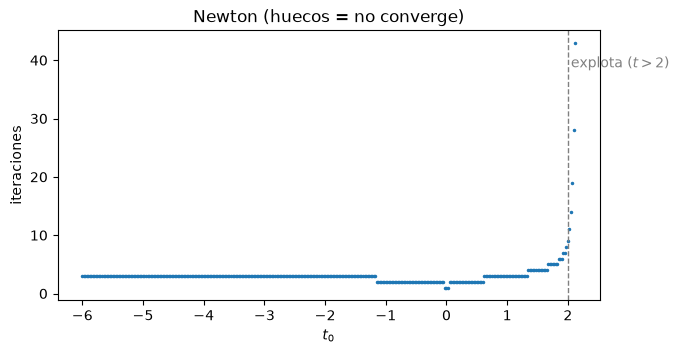

converge para 326 de 361 valores de t0
mayor t0 que converge: 2.125
menor t0 que no converge: 2.150


In [3]:
t0s = np.linspace(-6, 3, 361)
iters = np.full(t0s.shape, np.nan)
for i, t0 in enumerate(t0s):
    r = newton_shooting(f, f_y, f_dy, 0, 1, left, right, t0, max_iter=50)
    if r.converged:
        iters[i] = r.iterations

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(t0s, iters, ".", ms=3)
ax.axvline(2, color="gray", ls="--", lw=1)
ax.text(2.05, np.nanmax(iters) * 0.9, "explota ($t > 2$)", color="gray")
ax.set_xlabel("$t_0$")
ax.set_ylabel("iteraciones")
ax.set_title("Newton (huecos = no converge)")
plt.show()

print(f"converge para {np.sum(~np.isnan(iters))} de {len(t0s)} valores "
      f"de t0")
print(f"mayor t0 que converge: {t0s[~np.isnan(iters)].max():.3f}")
print(f"menor t0 que no converge: {t0s[np.isnan(iters)].min():.3f}")

## Secante: iteraciones en función de $(t_0, t_1)$

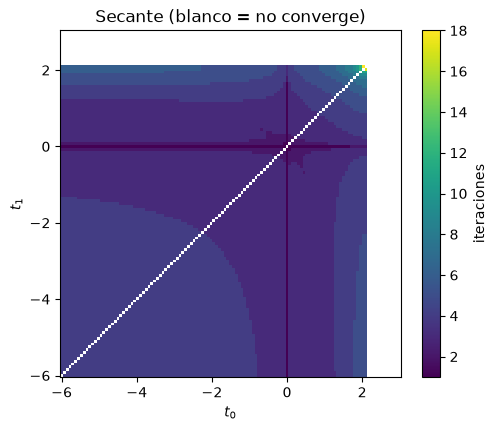

converge en el 80.4 % de los pares


In [4]:
grid = np.linspace(-6, 3, 121)
iters2 = np.full((grid.size, grid.size), np.nan)
for i, t1 in enumerate(grid):
    for j, t0 in enumerate(grid):
        if t0 == t1:
            continue
        r = secant_shooting(f, 0, 1, left, right, t0, t1, max_iter=50)
        if r.converged:
            iters2[i, j] = r.iterations

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.pcolormesh(grid, grid, iters2, shading="auto", cmap="viridis")
fig.colorbar(im, ax=ax, label="iteraciones")
ax.set_xlabel("$t_0$")
ax.set_ylabel("$t_1$")
ax.set_title("Secante (blanco = no converge)")
plt.show()

ok = ~np.isnan(iters2)
print(f"converge en el {100 * ok.mean():.1f} % de los pares")

Las zonas en blanco corresponden a valores iniciales en la región donde
la solución explota, o a pares cuya recta secante lleva la iteración a esa
región. El límite no es exactamente $t = 2$: con paso $h = 0.1$, RK4 puede
"saltarse" la singularidad cuando está muy cerca de $x = 1$ y devolver un
valor finito (aunque sin sentido) de $F$.

Con valores iniciales razonables, ambos métodos convergen; Newton lo hace
en menos iteraciones, a cambio de integrar un sistema el doble de grande en
cada paso.

## Cuando hay dos soluciones

Si cambiamos la condición derecha por $2\, y(1) + y'(1) = 2 \ln 2 + 1/2$,
$\ln(1 + x)$ sigue siendo solución, pero

$$
F(t) = 2t + 2\ln(2 - t) + \frac{1 - t}{2 - t} - 2\ln 2 - \frac{1}{2}
$$

tiende a $-\infty$ en los dos extremos de su dominio y tiene **dos
raíces**: $t^\ast = 0$ y otra cerca de $t \approx 1.094$. El problema de
contorno tiene dos soluciones, y el método de disparo encuentra una u otra
según el valor inicial.

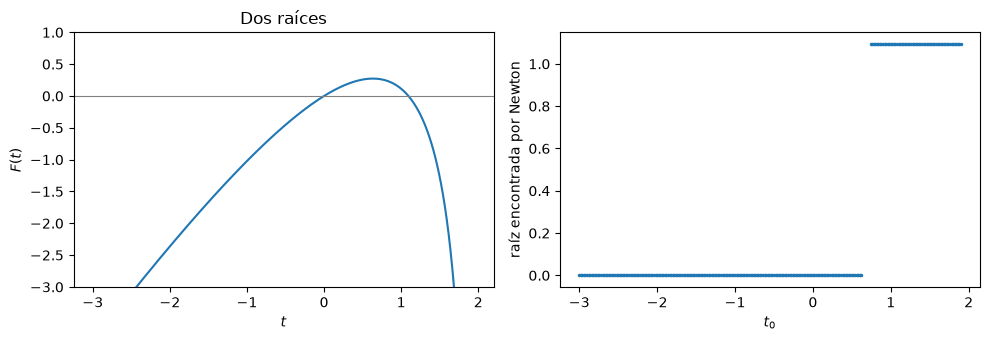

raíces encontradas: [0.     1.0944]


In [5]:
right_two = Robin(2, 1, 2 * np.log(2) + 0.5)


def F_two(t):
    return (2 * t + 2 * np.log(2 - t) + (1 - t) / (2 - t)
            - 2 * np.log(2) - 0.5)


roots = []
t0s_two = np.linspace(-3, 1.9, 246)
found = np.full(t0s_two.shape, np.nan)
for i, t0 in enumerate(t0s_two):
    r = newton_shooting(f, f_y, f_dy, 0, 1, left, right_two, t0)
    if r.converged:
        found[i] = r.t

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ts = np.linspace(-3, 1.95, 400)
ax1.plot(ts, F_two(ts))
ax1.axhline(0, color="gray", lw=0.8)
ax1.set_ylim(-3, 1)
ax1.set_xlabel("$t$")
ax1.set_ylabel("$F(t)$")
ax1.set_title("Dos raíces")
ax2.plot(t0s_two, found, ".", ms=3)
ax2.set_xlabel("$t_0$")
ax2.set_ylabel("raíz encontrada por Newton")
plt.tight_layout()
plt.show()

print("raíces encontradas:", np.unique(np.round(found[~np.isnan(found)],
                                                 4)))

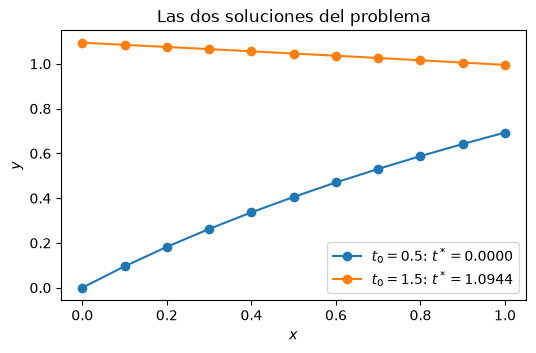

In [6]:
xs = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
for t0 in [0.5, 1.5]:
    r = newton_shooting(f, f_y, f_dy, 0, 1, left, right_two, t0)
    ax.plot(r.x, r.y, "o-", label=f"$t_0 = {t0}$: $t^* = {r.t:.4f}$")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Las dos soluciones del problema")
ax.legend()
plt.show()

## Comparación con `scipy.integrate.solve_bvp`

Volvemos al problema con solución única. `solve_bvp` lo resuelve
directamente por colocación (orden 4), sin disparo. Le pasamos el sistema
de primer orden y las condiciones de contorno como residuos. Igual que el
disparo, necesita una estimación inicial, y con varias soluciones también
puede acabar en cualquiera de ellas.

In [7]:
def system(x, u):
    return np.vstack([u[1], f(x, u[0], u[1])])


def bc(ua, ub):
    return np.array([left.residual(ua[0], ua[1]),
                     right.residual(ub[0], ub[1])])


x_init = np.linspace(0, 1, 11)
sol = solve_bvp(system, bc, x_init, np.zeros((2, x_init.size)), tol=1e-8)
print(sol.message)

newt = newton_shooting(f, f_y, f_dy, 0, 1, left, right, t0=1.0, tol=1e-10)
sec = secant_shooting(f, 0, 1, left, right, 1.0, 0.8, tol=1e-10)
exact = np.log1p(newt.x)
bvp_vals = sol.sol(newt.x)[0]

for name, vals in [("secante", sec.y), ("Newton", newt.y),
                   ("solve_bvp", bvp_vals)]:
    print(f"{name:10s} error máximo frente a la exacta: "
          f"{np.max(np.abs(vals - exact)):.2e}")
print(f"máx |Newton - solve_bvp| = {np.max(np.abs(newt.y - bvp_vals)):.2e}")

The algorithm converged to the desired accuracy.
secante    error máximo frente a la exacta: 2.53e-06
Newton     error máximo frente a la exacta: 2.53e-06
solve_bvp  error máximo frente a la exacta: 1.73e-11
máx |Newton - solve_bvp| = 2.53e-06


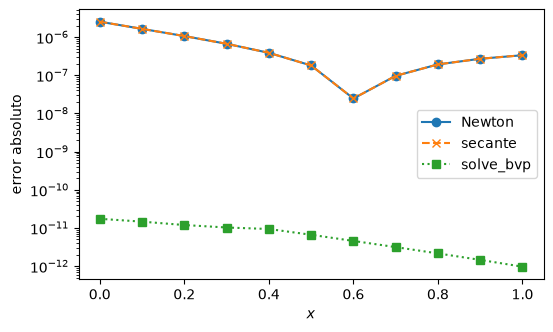

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(newt.x, np.abs(newt.y - exact) + 1e-17, "o-", label="Newton")
ax.semilogy(sec.x, np.abs(sec.y - exact) + 1e-17, "x--", label="secante")
ax.semilogy(newt.x, np.abs(bvp_vals - exact) + 1e-17, "s:",
            label="solve_bvp")
ax.set_xlabel("$x$")
ax.set_ylabel("error absoluto")
ax.legend()
plt.show()

`solve_bvp` sale mucho más preciso porque **refina la malla** hasta cumplir
su tolerancia (`tol=1e-8`), mientras que el disparo usa una malla fija de
$N = 10$ subintervalos. El error del disparo es el de RK4 con $h = 0.1$, y
se reduce aumentando $N$, como vemos a continuación.

## Orden de convergencia en $N$

Con la tolerancia de las iteraciones muy por debajo del error de
discretización, el error del disparo es el de RK4: al duplicar $N$ debería
dividirse por unas 16 veces.

In [9]:
ns = [5, 10, 20, 40, 80]
errors = []
for n in ns:
    r = newton_shooting(f, f_y, f_dy, 0, 1, left, right, t0=1.0, n=n,
                        tol=1e-13)
    errors.append(np.max(np.abs(r.y - np.log1p(r.x))))

for i, (n, e) in enumerate(zip(ns, errors)):
    ratio = "" if i == 0 else f"{errors[i - 1] / e:6.1f}"
    print(f"N = {n:3d}  error = {e:.3e}  {ratio}")

N =   5  error = 4.465e-05  
N =  10  error = 2.528e-06    17.7
N =  20  error = 1.495e-07    16.9
N =  40  error = 9.080e-09    16.5
N =  80  error = 5.592e-10    16.2
